# Hw2.2 — Аналіз файлу 2017_jun_final.csv
Результати опитування розробників (червень 2017)

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.style.use("ggplot")

## 1–2. Читання файлу та перші рядки

In [7]:
df = pd.read_csv("2017_jun_final.csv")
df_raw = df.copy()
df.head()

,N,Посада,Мова програмування,Спеціалізація,Загальний досвід роботи,Досвід роботи на поточному місці,Зарплата на місяць,Зміна зарплати за 12 місяців,Місто,Розмір компанії,...,Ще студент,Рівень англійської,Предметна область,Дата заповнення,User.Agent,exp,current_job_exp,salary,Валюта,cls
0,1,Junior QA engineer,NaN,Manual QA,0.5,0.5,400,0,Харків,до 10 осіб,...,True,Pre-intermediate (нище середнього),"iOS,eCommerce",12/06/2017 12:38:08,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,0.5,0.5,400,NaN,QA
1,2,Junior QA engineer,NaN,Manual QA,менше 3 місяців,менше 3 місяців,430,130,Харків,більше 1000 осіб,...,True,Upper-Intermediate (вище середнього),Веб-розробка,12/06/2017 12:42:51,Mozilla/5.0 (iPad; CPU OS 10_2_1 like Mac OS X...,0.0,0.0,430,NaN,QA
2,3,Software Engineer,C#/.NET,NaN,4,1,2500,800,Київ,до 1000 осіб,...,False,Intermediate (середній),"Веб-розробка,Корпоративні системи",12/06/2017 13:02:47,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,4.0,1.0,2500,NaN,DEV
3,4,Software Engineer,JavaScript,NaN,5,4,2000,400,Одеса,до 200 осіб,...,False,Pre-intermediate (нище середнього),"Desktop Applications,Веб-розробка",12/06/2017 13:03:01,Mozilla/5.0 (Windows NT 6.1; Win64; x64) Apple...,5.0,4.0,2000,NaN,DEV
4,5,Senior Software Engineer,JavaScript,NaN,10 і більше років,0.5,4500,500,Інше,до 10 осіб,...,False,Intermediate (середній),"Desktop Applications,Веб-розробка",12/06/2017 13:03:47,Mozilla/5.0 (iPhone; CPU iPhone OS 10_3_2 like...,10.0,0.5,4500,NaN,DEV


In [8]:
def find_col(frame, *keys):
    """Шукає стовпець за частиною назви (назви в датасеті можуть бути рос./укр.)."""
    for k in keys:
        for c in frame.columns:
            if c.lower() == k.lower():
                return c
    for k in keys:
        for c in frame.columns:
            if k.lower() in c.lower():
                return c
    raise KeyError(f"Не знайдено стовпець за ключами {keys}")

LANG = find_col(df, "Язык.программирования", "Мова.програмування", "програмування", "программирования")
POS  = find_col(df, "Должность", "Посада")
SAL = next(c for c in df.columns if c.lower().startswith("зарплат") or "salary" in c.lower())
print("Мова:", LANG, "| Посада:", POS, "| Зарплата:", SAL)

Мова: Мова програмування | Посада: Посада | Зарплата: Зарплата на місяць


## 3. Розмір таблиці

In [9]:
df.shape

(8704, 25)

## 4. Типи стовпців

In [10]:
df.dtypes

,0
N,int64
Посада,object
Мова програмування,object
Спеціалізація,object
Загальний досвід роботи,object
Досвід роботи на поточному місці,object
Зарплата на місяць,int64
Зміна зарплати за 12 місяців,int64
Місто,object
Розмір компанії,object


## 5. Частка пропусків у кожній колонці

In [11]:
print((df.isnull().sum() / len(df)).round(3).sort_values(ascending=False).to_string())

Валюта                              0.999
Спеціалізація                       0.829
Мова програмування                  0.442
cls                                 0.181
Університет                         0.041
Предметна область                   0.026
N                                   0.000
Посада                              0.000
Загальний досвід роботи             0.000
Місто                               0.000
Зміна зарплати за 12 місяців        0.000
Зарплата на місяць                  0.000
Досвід роботи на поточному місці    0.000
Вік                                 0.000
Розмір компанії                     0.000
Стать                               0.000
Тип компанії                        0.000
Рівень англійської                  0.000
Ще студент                          0.000
Освіта                              0.000
Дата заповнення                     0.000
exp                                 0.000
User.Agent                          0.000
salary                            

## 6. Видалення всіх стовпців з пропусками, крім стовпця з мовою програмування

In [12]:
cols_with_nan = [c for c in df.columns if df[c].isnull().any() and c != LANG]

protected = [c for c in (POS, SAL) if c in cols_with_nan]
if protected:
    print("Увага! Залишаємо потрібні для аналізу стовпці:", protected)
cols_with_nan = [c for c in cols_with_nan if c not in protected]

df = df.drop(columns=cols_with_nan)
df.shape

(8704, 20)

## 7. Повторна перевірка пропусків

In [13]:
print((df.isnull().sum() / len(df)).round(3).to_string())

N                                   0.000
Посада                              0.000
Мова програмування                  0.442
Загальний досвід роботи             0.000
Досвід роботи на поточному місці    0.000
Зарплата на місяць                  0.000
Зміна зарплати за 12 місяців        0.000
Місто                               0.000
Розмір компанії                     0.000
Тип компанії                        0.000
Стать                               0.000
Вік                                 0.000
Освіта                              0.000
Ще студент                          0.000
Рівень англійської                  0.000
Дата заповнення                     0.000
User.Agent                          0.000
exp                                 0.000
current_job_exp                     0.000
salary                              0.000


## 8–9. Видалення рядків із пропусками (`dropna`) та новий розмір

In [14]:
df = df.dropna()
print("Новий розмір:", df.shape)

Новий розмір: (4854, 20)


## 10–11. Таблиця `python_data` (спеціалісти з Python)

In [15]:
df[SAL] = pd.to_numeric(df[SAL], errors="coerce")
python_data = df[df[LANG].astype(str).str.contains("Python", case=False)]
print("Розмір python_data:", python_data.shape)
python_data.head()

Розмір python_data: (207, 20)


,N,Посада,Мова програмування,Загальний досвід роботи,Досвід роботи на поточному місці,Зарплата на місяць,Зміна зарплати за 12 місяців,Місто,Розмір компанії,Тип компанії,Стать,Вік,Освіта,Ще студент,Рівень англійської,Дата заповнення,User.Agent,exp,current_job_exp,salary
12,13,Software Engineer,Python,1,менше 3 місяців,800,200,Київ,до 50 осіб,Аутсорсингова,чоловіча,26,Вища,False,Pre-intermediate (нище середнього),12/06/2017 13:05:54,Mozilla/5.0 (Windows NT 6.1; Win64; x64) Apple...,1.0,0.0,800
68,69,Software Engineer,Python,1.5,0.5,900,900,Київ,до 10 осіб,Стартап,чоловіча,21,Неповна Вища,True,Upper-Intermediate (вище середнього),12/06/2017 13:11:17,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,1.5,0.5,900
87,88,Junior Software Engineer,Python,0.5,0.5,600,0,Київ,до 10 осіб,Аутсорсингова,чоловіча,19,Неповна Вища,True,Upper-Intermediate (вище середнього),12/06/2017 13:12:25,Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/53...,0.5,0.5,600
114,115,Junior Software Engineer,Python,1.5,0.5,685,250,Київ,до 1000 осіб,Аутсорсингова,чоловіча,21,Неповна Вища,False,Intermediate (середній),12/06/2017 13:14:52,Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/53...,1.5,0.5,685
143,144,Junior Software Engineer,Python,1,1,750,250,Київ,до 10 осіб,Аутсорсингова,чоловіча,21,Неповна Вища,True,Upper-Intermediate (вище середнього),12/06/2017 13:19:10,Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/53...,1.0,1.0,750


## 12. Групування за посадою (`groupby`)

In [16]:
grouped = python_data.groupby(POS)
grouped[SAL].count().sort_values(ascending=False)

,Зарплата на місяць
Посада,
Software Engineer,100
Junior Software Engineer,63
Senior Software Engineer,31
Technical Lead,11
System Architect,2


## 13. Мінімальна та максимальна зарплата за посадою (`agg`)

In [17]:
salary_stats = grouped.agg(min_salary=(SAL, "min"), max_salary=(SAL, "max"))
salary_stats

,min_salary,max_salary
Посада,,
Junior Software Engineer,100,1250
Senior Software Engineer,1300,9200
Software Engineer,500,5400
System Architect,3000,5000
Technical Lead,1425,6200


## 14. Функція `fill_avg_salary` та стовпець `avg`

In [18]:
def fill_avg_salary(row):
    """Середнє значення між мінімальною та максимальною зарплатою на місяць."""
    return (row["min_salary"] + row["max_salary"]) / 2

salary_stats["avg"] = salary_stats.apply(fill_avg_salary, axis=1)
salary_stats

,min_salary,max_salary,avg
Посада,,,
Junior Software Engineer,100,1250,675.0
Senior Software Engineer,1300,9200,5250.0
Software Engineer,500,5400,2950.0
System Architect,3000,5000,4000.0
Technical Lead,1425,6200,3812.5


## 15. Описова статистика для `avg`

In [19]:
salary_stats["avg"].describe()

,avg
count,5.000000
mean,3337.500000
std,1700.091909
min,675.000000
25%,2950.000000
50%,3812.500000
75%,4000.000000
max,5250.000000


## 16. Збереження в CSV

In [20]:
salary_stats.to_csv("python_salary_stats.csv", encoding="utf-8-sig")
print("Збережено: python_salary_stats.csv")

Збережено: python_salary_stats.csv


---
## Візуалізація (додаткові графіки)

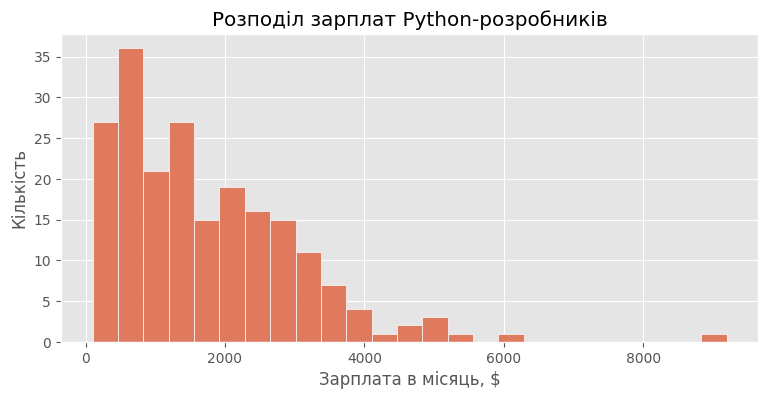

In [21]:

plt.figure(figsize=(9, 4))
plt.hist(python_data[SAL].dropna(), bins=25, color="#e07a5f", edgecolor="white")
plt.title("Розподіл зарплат Python-розробників")
plt.xlabel("Зарплата в місяць, $"); plt.ylabel("Кількість")
plt.show()

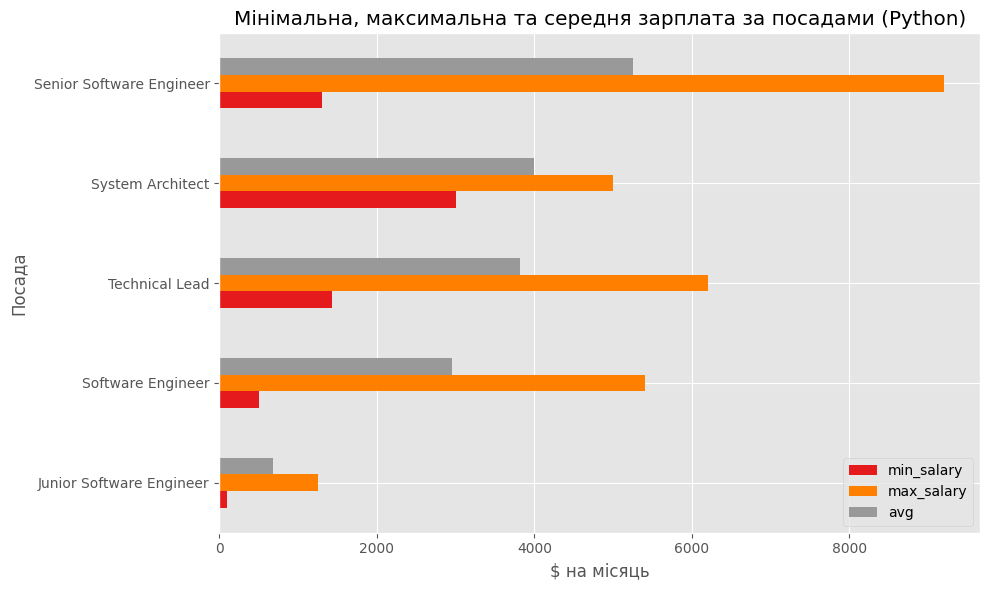

In [22]:

salary_stats.sort_values("avg").plot(kind="barh", figsize=(10, 6), colormap="Set1")
plt.title("Мінімальна, максимальна та середня зарплата за посадами (Python)")
plt.xlabel("$ на місяць")
plt.tight_layout()
plt.show()

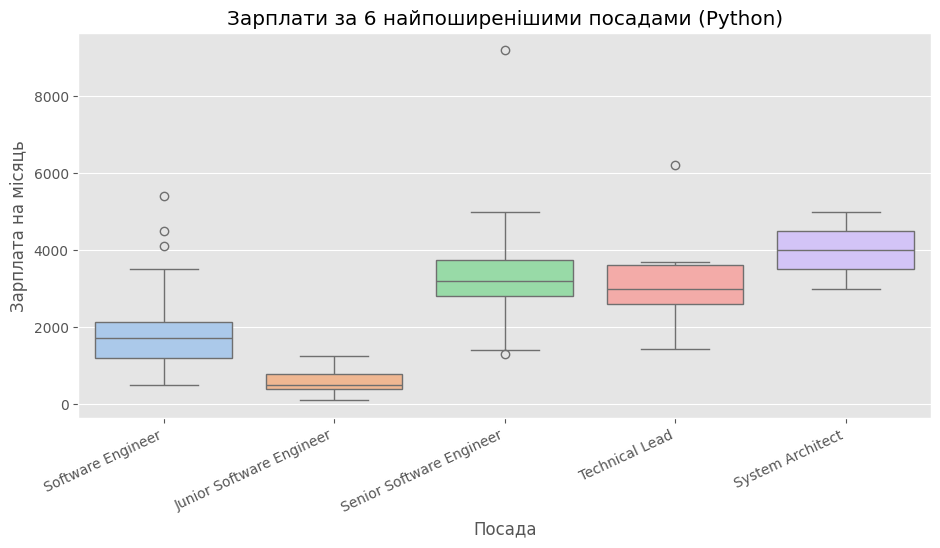

In [23]:

top_pos = python_data[POS].value_counts().head(6).index
plt.figure(figsize=(11, 5))
sns.boxplot(data=python_data[python_data[POS].isin(top_pos)], x=POS, y=SAL, hue=POS,
            palette="pastel", legend=False)
plt.xticks(rotation=25, ha="right")
plt.title("Зарплати за 6 найпоширенішими посадами (Python)")
plt.show()

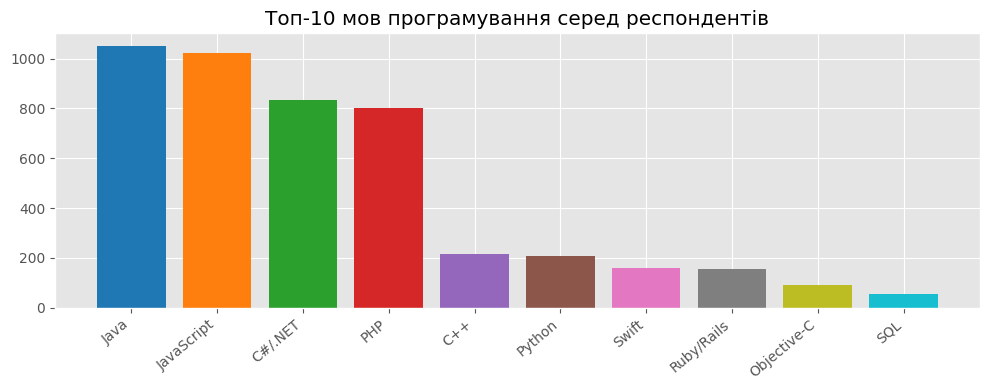

In [24]:

lang_counts = df_raw[LANG].value_counts().head(10)
plt.figure(figsize=(10, 4))
plt.bar(lang_counts.index, lang_counts.values, color=plt.cm.tab10.colors[:len(lang_counts)])
plt.xticks(rotation=40, ha="right")
plt.title("Топ-10 мов програмування серед респондентів")
plt.tight_layout()
plt.show()

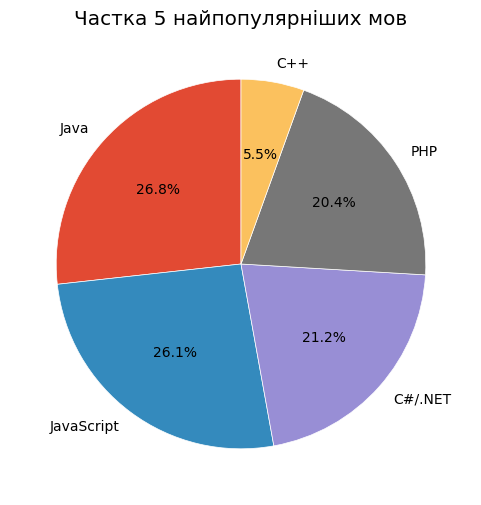

In [25]:

top5 = df_raw[LANG].value_counts().head(5)
plt.figure(figsize=(6, 6))
plt.pie(top5.values, labels=top5.index, autopct="%1.1f%%", startangle=90,
        wedgeprops={"edgecolor": "white"})
plt.title("Частка 5 найпопулярніших мов")
plt.show()